# 02 How agents are explained, and what is wrong with it

**Act 1. Nothing is needed: no key, no model, no network.** The live agent has already
been run by the notebook `03_produce_agentshap_live.ipynb`; its results are in `data/agentshap/`.
The counterfactual runs are in `data/full_cf_stopwords_results.csv`.

## Tracing vs explanation

A **trace** is a record of what happened: which calls, in what order, with which
arguments and responses. It is a fact about a run, and it can be recorded in full
(LangSmith, OpenTelemetry, harness logs).

An **explanation** is a claim about *why* it happened: "the agent called `send_money`
because it read an injection in the file". This is a causal claim about a world
that did not happen: without the injection, the call would not have occurred. It cannot be recorded;
it can only be measured or inferred.

Why explaining an agent is harder than explaining a classical model:

| | classical model | agent |
|---|---|---|
| output | a number, a class | text and a sequence of actions |
| one evaluation of $v(S)$ | a forward pass | a full agent run with tool calls |
| stochasticity | usually none | always present: one run is one sample |
| gradients | available | not through an API |
| comparing outcomes | difference of numbers | a text similarity metric, with its own noise |
| redundancy | correlated features | tools and rules that substitute for each other |

Every coalition is a separate model run. Exact Shapley over $n$ components
is $2^n$ runs, and each one is a random variable.

## What exists for explaining agents

Shapley attribution for agents is an active area, but there is little ready-to-use code.
Checked on 27.09.2026 (GitHub API, PyPI, Semantic Scholar).

| work | what it attributes | code, out of the box | what it measures |
|---|---|---|---|
| **AgentSHAP**, Horovicz, arXiv:2512.12597 (2025) | agent tools | yes, inside [GenAISHAP/TokenSHAP](https://github.com/GenAISHAP/TokenSHAP), black-box | Shapley over tool presence; $v(S)$ is the similarity of the response to the full one |
| **TokenSHAP**, Horovicz & Goldshmidt, NLP4Science 2024, doi:10.18653/v1/2024.nlp4science-1.1 | prompt tokens | same repository, PyPI `tokenshap` 0.2.2 (2024) | the same, over tokens |
| SkillShapley, arXiv:2608.13173 (2026) | skill steps | no | Shapley with adaptive coalition sampling |
| Understanding and Optimizing Agentic Workflows via Shapley value, arXiv:2502.00510 (2025) | workflow components | — | Shapley |
| ContextCite, Cohen-Wang et al., NeurIPS 2024 | context sentences | [MadryLab/context-cite](https://github.com/MadryLab/context-cite), PyPI `context-cite`; needs logprobs | a linear surrogate on random ablations |
| AttriBoT, Liu et al., arXiv:2411.15102 | context chunks | [r-three/AttriBoT](https://github.com/r-three/AttriBoT); needs logprobs | fast leave-one-out |
| LLMLingua / LongLLMLingua, EMNLP 2023 / ACL 2024, doi:10.18653/v1/2023.emnlp-main.825, 10.18653/v1/2024.acl-long.91 | tokens / prompt chunks | [microsoft/LLMLingua](https://github.com/microsoft/LLMLingua), PyPI `llmlingua` | not attribution: perplexity under a small LM, for compression |
| Mosca et al., a survey of SHAP for NLP, COLING 2022 | — | a survey, no code | — |
| Jiang et al., How can we know what LMs know?, TACL 2020 | — | the LPAQA prompt archive | sensitivity of the answer to wording, not attribution |

For a black-box agent, exactly one thing plugs in out of the box: **AgentSHAP**.
So that is what we take apart. Over nine months, Semantic Scholar shows
one citation for it, in the related work of a paper on provenance.

How it works: $v(S)$ is the TF-IDF cosine similarity between the agent's response with the tool set
$S$ and the response with the full set $N$. A tool's contribution is its Shapley
value in this game; efficiency is ensured by normalization.

In [1]:
import sys; sys.path.insert(0, "..")
import json
from itertools import combinations
from math import factorial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from agent import NoiseFloor, TOOL_NAMES
from agent.attribution import corrected_contributions, shapley_from_occlusion, tool_occlusion_importance
from bench.stats import bootstrap_order_prob, min_repeats, wilson_ci

pd.set_option("display.precision", 4)
DATA = "../data/agentshap/"

def load_runs(name):
    df = pd.read_csv(DATA + f"{name}_coalitions.csv" if name == "notool" else DATA + f"{name}.csv")
    return df[df.combination_key != "baseline"], df[df.combination_key == "baseline"]

finance, finance_base = load_runs("finance")
notool, notool_base = load_runs("notool")
shap_lib = pd.concat([pd.read_csv(DATA + "finance_shapley.csv"),
                      pd.read_csv(DATA + "notool_shapley.csv")]).set_index("prompt")
nf = NoiseFloor.from_json(DATA + "noise_floor.json")

# Critique A: implementation

## A1. $n$ rows, not $2^n$

In the tutorial, `sampling_ratio=0.0` carries the comment "full enumeration,
$2^n = 16$ combinations". Let us look at what is actually in `results_df`.

In [2]:
print(f"prompt: {finance.prompt.iloc[0]!r}")
print(f"rows in results_df: {len(finance)}   (2^n would be {2 ** len(TOOL_NAMES)})\n")
print(finance[["tools_available", "similarity"]].to_string(index=False))

prompt: "What's the weather in New York and how is AAPL stock doing today?"
rows in results_df: 4   (2^n would be 16)

                      tools_available  similarity
   calculate+get_news+get_stock_price      0.2256
       calculate+get_news+get_weather      0.2635
 get_news+get_stock_price+get_weather      0.6246
calculate+get_stock_price+get_weather      0.6830


The library enumerates only the "all but one" coalitions
(`agent_shap.py`, `_get_result_per_combination`, "essential combinations"),
and adds extra ones as a `sampling_ratio` fraction of the rest. At zero there are none.
A reason not to trust comments, including your own.

## A2. Shapley degeneracy

`sampling_ratio` is a parameter of `analyze()` (default 0.5): what fraction
of the "non-essential" coalitions to sample in addition. The library always runs the $n$
coalitions of the form $N \setminus \{i\}$, "all but one", and from the remaining
$2^n - 1 - n$ non-empty ones it randomly adds
$\lfloor (2^n - 1 - n) \cdot \texttt{sampling\_ratio} \rfloor$
(`agent_shap.py`, `_get_result_per_combination`). With `sampling_ratio=1`
all coalitions are enumerated; with `sampling_ratio=0`, not a single
extra one. So with `sampling_ratio=0` the library has only the
coalitions $N \setminus \{i\}$.

**Occlusion** (covering something up) is the simplest attribution method:
remove one component, keep the rest, and see how much the output
changed. The change is the component's importance. The name comes from computer
vision: there, a gray square covers part of the image and one checks whether
the classifier's confidence dropped (Zeiler & Fergus, 2014). In AgentSHAP the component is
a tool, the output is the agent's response, and the change is measured through similarity
to the response with the full set:

$$\mathrm{occ}_i = v(N) - v(N \setminus \{i\}) = 1 - v(N \setminus \{i\}),$$

where $v(N) = 1$ is the similarity of the full response to itself (we will return to this one
in A3). These are exactly the $n$ "all but one" coalitions, that is,
exactly what the library runs with `sampling_ratio=0`.

The Shapley value cannot be computed from such coalitions alone: it needs all
$2^n$. So the library does something else: it takes occlusion and normalizes it.
The normalization, reconstructed from the code:

$$\varphi_i = \frac{\mathrm{occ}_i - \min_j \mathrm{occ}_j}{\sum_k \mathrm{occ}_k - n \min_j \mathrm{occ}_j}$$

We check it on all six saved runs against what the library
itself returned.

In [3]:
runs = pd.concat([finance, notool])
check = []
for prompt, g in runs.groupby("prompt", sort=False):
    closed = shapley_from_occlusion(tool_occlusion_importance(g, TOOL_NAMES))
    check.append({"prompt": prompt[:45], "max. discrepancy": np.abs(closed - shap_lib.loc[prompt, TOOL_NAMES]).max()})
pd.DataFrame(check).set_index("prompt")

,max. discrepancy
prompt,
What's the weather in New York and how is AAP,5.5511e-17
What is the capital of France?,1.1102e-16
Who wrote Anna Karenina?,1.1102e-16
Translate 'good morning' into Spanish.,1.6653e-16
What does the acronym CPU stand for?,4.1633e-16
Name three primary colors.,1.6653e-16


Agreement up to $10^{-16}$, that is, up to machine precision: the closed form
is exactly what the library computes.

What follows from it. Rewrite it as

$$\varphi_i = a \cdot \mathrm{occ}_i + b, \qquad
a = \frac{1}{\sum_k \mathrm{occ}_k - n \min_j \mathrm{occ}_j} > 0, \qquad
b = -a \min_j \mathrm{occ}_j .$$

On a single prompt, $a$ and $b$ are constants shared by all tools,
and $a > 0$. So "Shapley" here is a **strictly increasing affine function
of occlusion**: the larger the occlusion, the larger $\varphi$, and nothing else.
Two consequences:

1. **The tool ranking is identical to the occlusion ranking**, on any
   prompt, for any similarity values. "Shapley" adds no information beyond
   occlusion: it is the same occlusion, shifted
   and stretched.
2. **The minimal tool (the one with the smallest occlusion) always gets zero:** at
   $\mathrm{occ}_i = \min_j \mathrm{occ}_j$ the numerator vanishes.
   Not because the tool had no effect, but because it is the minimal one.
   We return to this in A4.

*Note.* Other methods degenerate on the same coalitions too: LIME reduces to $\tfrac{3}{7}\,\mathrm{occ}_i + c$. So "the methods
agree" confirms nothing here: it is one function at different scales.

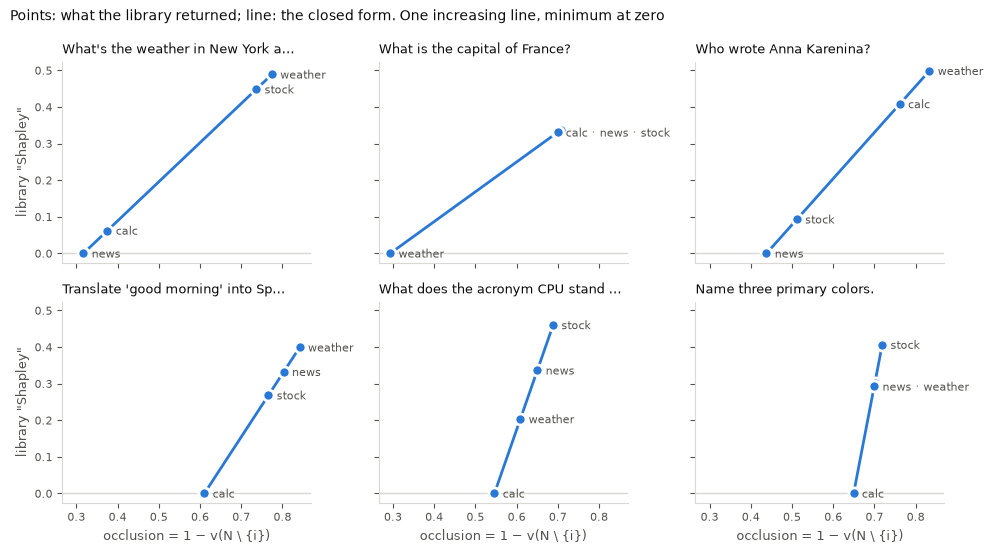

In [4]:
# dependence plot: the library's "Shapley" vs occlusion, one prompt per panel
INK, INK_2, GRID, SERIES = "#0b0b0b", "#52514e", "#d9d8d4", "#2a78d6"
SHORT = {"get_weather": "weather", "get_stock_price": "stock", "calculate": "calc", "get_news": "news"}

fig, axes = plt.subplots(2, 3, figsize=(10, 5.6), sharex=True, sharey=True)
for ax, (prompt, g) in zip(axes.flat, runs.groupby("prompt", sort=False)):
    occ = tool_occlusion_importance(g, TOOL_NAMES)
    phi = shap_lib.loc[prompt, TOOL_NAMES].astype(float)
    x = np.linspace(occ.min(), occ.max(), 2)
    a = 1 / (occ.sum() - len(occ) * occ.min())
    ax.plot(x, a * (x - occ.min()), color=SERIES, lw=2, zorder=1)          # closed form
    ax.scatter(occ, phi, s=64, color=SERIES, edgecolor="white", linewidth=2, zorder=2)  # library
    # points that nearly coincide get a single label
    groups = []
    for tool in phi.sort_values().index:
        if groups and abs(phi[tool] - phi[groups[-1][0]]) < 0.03 and abs(occ[tool] - occ[groups[-1][0]]) < 0.03:
            groups[-1].append(tool)
        else:
            groups.append([tool])
    for grp in groups:
        ax.annotate(" · ".join(SHORT[t] for t in grp), (occ[grp[0]], phi[grp[0]]), xytext=(6, -3),
                    textcoords="offset points", fontsize=8, color=INK_2)
    ax.axhline(0, color=GRID, lw=1, zorder=0)
    ax.set_title(prompt if len(prompt) <= 34 else prompt[:32] + "…", fontsize=9, color=INK, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRID)
    ax.tick_params(colors=INK_2, labelsize=8)
for ax in axes[1]:
    ax.set_xlabel("occlusion = 1 − v(N \\ {i})", fontsize=9, color=INK_2)
for ax in axes[:, 0]:
    ax.set_ylabel("library \"Shapley\"", fontsize=9, color=INK_2)
fig.suptitle("Points: what the library returned; line: the closed form. One increasing line, minimum at zero",
             fontsize=10, color=INK, x=0.01, ha="left")
plt.tight_layout(); plt.show()

## A3. An unreachable baseline

In `token_shap/base.py`, `OpenAIModel.generate()` and `generate_with_tools()`
hard-code `temperature=0.5` (lines 328 and 370 in version `28b2f2c`); there is no parameter.
So two runs with the same full toolset give different responses,
and the similarity of a response to itself is not one, as in the formula, but
$\nu = \mathbb E[\cos(\text{response}(N), \text{response}'(N))] < 1$.

noise floor  nu = 0.6653 ± 0.1079   (27 comparisons, 3 prompts, qwen2.5:3b)
bias       1 - nu = 0.3347
behavioural noise: 0.0% of runs with a different tool set


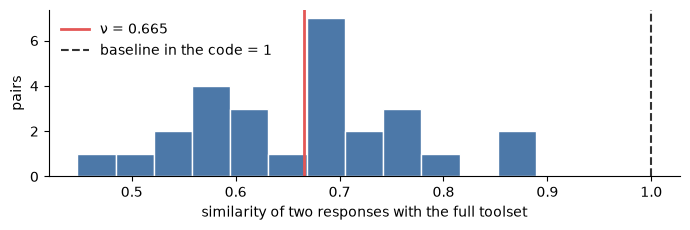

In [5]:
print(nf)
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.hist(nf.samples, bins=12, color="#4C78A8", edgecolor="white")
ax.axvline(nf.nu, color="#E45756", lw=2, label=f"ν = {nf.nu:.3f}")
ax.axvline(1.0, color="#333", ls="--", lw=1.5, label="baseline in the code = 1")
ax.set_xlabel("similarity of two responses with the full toolset")
ax.set_ylabel("pairs")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## A4. The dummy axiom

A tool the agent did not call must get zero. Five prompts
where no tool is needed at all.

In [6]:
table = shap_lib.loc[notool.prompt.unique(), TOOL_NAMES]
table["sum"] = table.sum(axis=1)
table["exact zeros"] = (table[TOOL_NAMES].abs() < 1e-12).sum(axis=1)
print(table.round(4).to_string())

used = [c for c in notool.columns if c.startswith("used_")]
calls = pd.concat([notool, notool_base]).groupby("prompt", sort=False)[used].sum()
print("\ntool calls on these prompts, across all analyze() runs:")
print(calls.to_string())

                                        get_weather  get_stock_price  calculate  get_news  sum  exact zeros
prompt                                                                                                     
What is the capital of France?               0.0000           0.3381     0.3305    0.3314  1.0            1
Who wrote Anna Karenina?                     0.4989           0.0931     0.4080    0.0000  1.0            1
Translate 'good morning' into Spanish.       0.3993           0.2683     0.0000    0.3324  1.0            1
What does the acronym CPU stand for?         0.2034           0.4602     0.0000    0.3364  1.0            1
Name three primary colors.                   0.3012           0.4065     0.0000    0.2923  1.0            1

tool calls on these prompts, across all analyze() runs:
                                        used_get_news
prompt                                               
What is the capital of France?                    0.0
Who wrote Anna Karenina? 

The sum in every row is exactly 1: efficiency holds by normalization, and the same normalization
forces the unit to be handed out to tools the agent did not call. But
one tool per row gets an exact zero: the one with the smallest
occlusion. This follows from the form: normalization shifts the minimum to zero.
The dummy axiom "holds" for exactly one tool per prompt, by accident.

## A5. Can this be fixed by replacing the baseline

Idea: if the bias comes from the unreachable one, replace it with the measured
ceiling $\nu$:

```python
contribution_i = 1 - similarity(N \ {i})              # before
contribution_i = max(0, nu - similarity(N \ {i}))     # after
```

For a tool that was not called, `similarity` stays around $\nu$, and the contribution
drops to zero. A testable prediction: the mean occlusion on no-tool prompts
should be close to $1 - \nu$.

First we take $\nu$ measured on prompts **with** tools.

In [7]:
check = pd.DataFrame({
    "mean occlusion": notool.groupby("prompt", sort=False)
        .apply(lambda g: tool_occlusion_importance(g, TOOL_NAMES).mean()),
})
check["prediction 1 - ν (global)"] = nf.bias
check.round(3)

,mean occlusion,prediction 1 - ν (global)
prompt,,
What is the capital of France?,0.600,0.335
Who wrote Anna Karenina?,0.636,0.335
Translate 'good morning' into Spanish.,0.755,0.335
What does the acronym CPU stand for?,0.623,0.335
Name three primary colors.,0.692,0.335


The prediction does not match: occlusion is almost twice as large. The similarity ceiling
depends on the prompt. A response built on tool data is nearly deterministic;
free text ("name the three primary colors") is not. So the notebook `03_produce_agentshap_live.ipynb`
also measured $\nu$ on each no-tool prompt, with ten runs each.

In [8]:
nf_p = {p: NoiseFloor(**d) for p, d in json.loads(open(DATA + "noise_floor_notool.json").read()).items()}

rows = []
for prompt, g in notool.groupby("prompt", sort=False):
    n = nf_p[prompt]
    corrected = corrected_contributions(g, TOOL_NAMES, n.nu)
    rows.append({"prompt": prompt[:40], "ν on the prompt": n.nu, "σ": n.sd,
                 "mean occlusion": tool_occlusion_importance(g, TOOL_NAMES).mean(),
                 "prediction 1 - ν": 1 - n.nu,
                 "max. contribution after correction": corrected.max(),
                 "all contributions ≤ 2σ": bool((corrected <= 2 * n.sd).all())})
pd.DataFrame(rows).set_index("prompt").round(3)

,ν on the prompt,σ,mean occlusion,prediction 1 - ν,max. contribution after correction,all contributions ≤ 2σ
prompt,,,,,,
What is the capital of France?,0.316,0.079,0.600,0.684,0.024,True
Who wrote Anna Karenina?,0.318,0.102,0.636,0.682,0.151,True
Translate 'good morning' into Spanish.,0.308,0.104,0.755,0.692,0.149,True
What does the acronym CPU stand for?,0.424,0.141,0.623,0.576,0.113,True
Name three primary colors.,0.274,0.048,0.692,0.726,0.000,True


With $\nu$ from the same prompt the prediction matches, and after the correction all contributions
of the uncalled tools lie within two standard deviations of the noise:
dummy holds. But:

1. the baseline is not one but $\nu$, **measured on the same prompt**;
2. that is another ten or so runs for every prompt being explained;
3. you cannot normalize: dividing near-zero contributions by their near-zero
   sum blows the noise back up to one;
4. and even then "zero" means "indistinguishable from noise on these runs",
   not "the tool had no effect".

The implementation critique can be fixed, but every fix costs runs.

# Critique B: the wrong question

Everything above can be fixed: full enumeration instead of "all but one", a measured
baseline, normalization without shifting the minimum. But let us return to necessity and sufficiency.

**Watson et al. (UAI 2021), Proposition 1.** The SHAP value function
$v(S) = \mathbb E[f(x_S, X_R)]$ is identically equal to the probability of
**sufficiency** of the factor "$x_S$ is fixed, the rest comes from the background".
AgentSHAP is the same: $v(S)$ is how similar the response with tools $S$ is
to the full one, that is, whether $S$ is enough to get the same response.
The Shapley value is the average gain in sufficiency.

The question "without what would the response have been different" is **necessity**, and it
is not posed anywhere in this construction (notebook 01). The critique holds for
an ideal implementation and survives any bug fix.

**Redundancy theorem.** If tools $i$ and $j$ are interchangeable:
for any $S \subseteq N \setminus \{i, j\}$,
$v(S \cup \{i\}) = v(S \cup \{j\}) = v(S \cup \{i, j\})$, then
$\varphi_i = \varphi_j > 0$, but $\text{PN}(i) = \text{PN}(j) = 0$.

*Proof.* PN = 0: without $i$, $j$ remains, and $v(N \setminus \{i\}) = v(N)$.
Equality follows from symmetry. Positivity: the marginal contribution of $i$
is positive on coalitions without $i$ and without $j$.

Two search tools and a calculator, exact Shapley by full enumeration:

In [9]:
def exact_shapley(v, players):
    n = len(players)
    return {i: sum(factorial(k) * factorial(n - k - 1) / factorial(n)
                   * (v(frozenset(S) | {i}) - v(frozenset(S)))
                   for k in range(n) for S in combinations([p for p in players if p != i], k))
            for i in players}

def v(S):
    return (1.0 if S & {"search_a", "search_b"} else 0.0) + (0.4 if "calc" in S else 0.0)

full = frozenset({"search_a", "search_b", "calc"})
pd.DataFrame({"Shapley": exact_shapley(v, sorted(full)),
              "PN": {i: float(v(full - {i}) != v(full)) for i in sorted(full)}})

,Shapley,PN
calc,0.4,1.0
search_a,0.5,0.0
search_b,0.5,0.0


Search A and search B split the contribution equally, although removing either one does not change the response.
With $k$ interchangeable tools each gets $1/k$: the more
overlap, the more negligible each one looks. For a detector with overlapping
rules this means that "rule importance" is undefined.

# The cost, in words.

Fine, let us measure necessity directly, by intervention. 468 real
agent runs: remove a word from the prompt and see whether the agent stopped
calling the tool. This is not an estimate but a direct measurement.

In [10]:
cf = pd.read_csv("../data/full_cf_stopwords_results.csv")
print(cf.head(3).to_string(index=False), "\n")

pn = cf.groupby("tool")["flipped"].agg(["sum", "count"])
pn["PN"] = pn["sum"] / pn["count"]
pn = pn.sort_values("PN", ascending=False)
for tool, row in pn.iterrows():
    lo, hi = wilson_ci(int(row["sum"]), int(row["count"]))
    print(f"{tool:<18} PN = {row['PN']:6.1%}  [{lo:5.1%}, {hi:5.1%}]  n = {int(row['count'])}")

       tool removed_words  called_before  called_after  flipped
get_weather  weather+like           True         False     True
get_weather  weather+like           True         False     True
get_weather  weather+like           True          True    False 

get_news           PN =  51.9%  [43.4%, 60.4%]  n = 129
get_stock_price    PN =  26.6%  [19.7%, 34.8%]  n = 128
get_weather        PN =  16.9%  [11.4%, 24.3%]  n = 130
calculate          PN =   2.5%  [ 0.7%,  8.6%]  n = 81


**What the Wilson confidence interval is.** The proportion $\hat p = k/n$ is an estimate
of a probability from $k$ "successes" out of $n$ trials. The best-known interval
for it is the normal approximation (the Wald interval):

$$\hat p \pm z\sqrt{\frac{\hat p(1-\hat p)}{n}}, \qquad z = 1.96 \text{ for } 95\,\%.$$

It breaks exactly where it matters to us: at small $n$ and proportions near 0 or 1.
At $k = 0$ it gives $[0; 0]$ ("never"), and at small $k$ it can go
negative.

The Wilson interval is built differently: it is all values of $p$ for which
the observed $\hat p$ does not contradict $p$ under a z-test, where the spread is taken
from $p$ itself, not from $\hat p$. The solution of this inequality:

$$\frac{\hat p + \frac{z^2}{2n}}{1 + \frac{z^2}{n}} \;\pm\;
\frac{z}{1 + \frac{z^2}{n}}\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}.$$

The center is shifted from $\hat p$ towards ½, the interval never leaves $[0; 1]$
and never collapses to a point. For large $n$ and proportions away from the edge it coincides
with Wald.

| $k$ out of $n$ | Wald | Wilson |
|---|---|---|
| 0 out of 3 | [0; 0] | [0; 0.56] |
| 2 out of 81 (`calculate`) | [−0.009; 0.059] | [0.007; 0.086] |
| 67 out of 129 (`get_news`) | [0.433; 0.606] | [0.434; 0.604] |

The implementation is `bench.stats.wilson_ci`. How many runs are needed before such frequencies
let us claim an ordering at all? We simulate an experiment with $n$ runs per tool
at true frequencies equal to the measured ones.

A tie is a separate category: the data do not determine the order at all.

In [11]:
rates = pn["PN"].to_dict()
print(f"{'n per tool':>16} {'correct order':>15} {'tie':>8} {'wrong':>9}")
for n_per in (3, 10, 50, 100):
    r = bootstrap_order_prob(rates, n_per, n_boot=50_000)
    print(f"{n_per:>16} {r['p_correct']:>15.1%} {r['p_tie']:>8.1%} {r['p_wrong']:>9.1%}")

      n per tool   correct order      tie     wrong
               3            0.7%    98.4%      0.9%
              10           28.6%    51.5%     19.9%
              50           84.3%     5.5%     10.2%
             100           94.1%     1.8%      4.0%


How many runs per tool are needed to tell neighbors in the ranking apart.
The standard sample-size formula for two proportions, two-sided test,
$\alpha = 0.05$, power **0.90**.

In [12]:
pairs = list(zip(pn.index, pn.index[1:]))
for t1, t2 in pairs:
    print(f"{t1:>16} vs {t2:<16} power 0.90: {min_repeats(rates[t1], rates[t2], power=0.90):>4}   "
          f"0.80: {min_repeats(rates[t1], rates[t2], power=0.80):>4}")

print("\nzero hits out of n is an interval, not zero:")
for n in (3, 30, 170):
    lo, hi = wilson_ci(0, n)
    print(f"  0 out of {n:>3}: [{lo:.3f}, {hi:.3f}]")

        get_news vs get_stock_price  power 0.90:   76   0.80:   57
 get_stock_price vs get_weather      power 0.90:  383   0.80:  287
     get_weather vs calculate        power 0.90:   86   0.80:   65

zero hits out of n is an interval, not zero:
  0 out of   3: [0.000, 0.561]
  0 out of  30: [0.000, 0.114]
  0 out of 170: [0.000, 0.022]


To tell `get_stock_price` from `get_weather` you need **383 runs**
per tool. And zero false positives out of 170 means
"less often than 2.2 %". That is how a defense
that never failed on the test set should be reported.


## Clusters: measure the spread over topics, not over runs

The Wilson interval treats all $n$ observations as independent. In test
sets this is almost never the case: prompts are generated from templates, grouped
by topic, attacks by scenario. Observations within one group resemble each
other, and the number of independent observations is really the number of groups,
not the number of rows.

In the data above this shows up in `calculate`: "PN = 2.5 %, n = 81" is two
different interventions pooled together.

In [13]:
print(cf.groupby(["tool", "removed_words"])["flipped"].agg(["sum", "count", "mean"])
        .rename(columns={"sum": "flips", "count": "n", "mean": "PN"}).round(3).to_string())

                               flips    n     PN
tool            removed_words                   
calculate       of                 0   47  0.000
                times              2   34  0.059
get_news        news+latest       67  129  0.519
get_stock_price stock+doing       34  128  0.266
get_weather     weather+like      22  130  0.169


Removing "of": zero changes out of 47; removing "times": 2 out of 34. The mean 2.5 %
describes not the tool but the proportion in which we mixed two interventions.
Add a third word and you get a different number.

How much this spoils the interval, we show by simulation. 10 topics with 15 prompts each;
each topic has its own true PN (mean 0.3, moderate spread between
topics). We compare two intervals for the **mean PN of the component over the whole
population of topics**, that is, on new topics that will show up in production,
not only on the 10 that made it into the test. The truth here is 0.3, the mean
of the distribution the topic PNs are drawn from.

This is the usual question: a detector must work on new attacks, not on the ones
it was measured on. If we were asking about PN on exactly these 10 topics,
only the runs within topics would be random, and Wilson would be nearly right.
For the new question the topics themselves are random too: the between-topic spread
adds to the run noise, and Wilson does not see it.

Two intervals:

- **Wilson** over all 150 observations as if independent;
- **cluster bootstrap**: resample whole topics, not individual prompts.

We count the fraction of simulations in which the interval covered the true mean. A correctly built
95 % interval should be at about 95 %.

In [14]:
rng = np.random.default_rng(0)
K, m, trials = 10, 15, 2000          # topics, prompts per topic, simulations
a, b = 1.2, 2.8                      # topic PN ~ Beta(a, b), mean 0.3
true_mean = a / (a + b)

hit_w = hit_c = 0
width_w, width_c = [], []
for _ in range(trials):
    flips = rng.binomial(m, rng.beta(a, b, K))                 # changes in each topic
    lo, hi = wilson_ci(flips.sum(), K * m)
    hit_w += lo <= true_mean <= hi
    width_w.append(hi - lo)
    boot = flips[rng.integers(0, K, (2000, K))].sum(axis=1) / (K * m)   # whole topics
    lo, hi = np.percentile(boot, [2.5, 97.5])
    hit_c += lo <= true_mean <= hi
    width_c.append(hi - lo)

print(f"{'':<22}{'covered truth':>15}{'mean width':>17}")
print(f"{'Wilson over prompts':<22}{hit_w / trials:>15.1%}{np.mean(width_w):>17.3f}")
print(f"{'bootstrap over topics':<22}{hit_c / trials:>15.1%}{np.mean(width_c):>17.3f}")

                        covered truth       mean width
Wilson over prompts             69.1%            0.143
bootstrap over topics           90.8%            0.262


The "95 %" Wilson interval covers the truth in roughly two cases out of three:
it is half as wide as it should be, because it counts 150 observations where
there are effectively 10 independent ones. The cluster bootstrap is closer to the stated 95 % (with
10 topics it is itself a bit optimistic), and its interval is twice as wide.

What to do with a test set built from topics or templates:

1. **Know the structure.** Store which topic, template, or scenario each
   example came from.
2. **Look at the spread between groups**, not only the overall proportion: one mean
   can hide groups with opposite behavior, like `of` and `times`.
3. **Build the interval over groups**: a cluster bootstrap, or at least
   a separate proportion for each group.
4. **The number of groups matters more than the number of examples.** Adding 100 prompts to the same topic
   barely narrows the interval; adding a new topic does.

### How "over prompts" differs from "over topics"

The estimate is the same: all changes divided by all runs. What differs is what
counts as an **independent observation**, and the width of the interval depends on that.

- **Over prompts** (Wilson): each of the 150 prompts is a separate coin flip.
  The variance of the estimate is $\approx p(1-p)/150$.
- **Over topics** (cluster bootstrap): topics are independent, while prompts within
  a topic are similar and the agent behaves almost identically on them. We resample
  whole topics, and the spread is determined by how much the topics differ.

An extreme case: in five topics out of ten the component is always necessary, in the other five
never. The mean is 0.5, and over prompts the interval comes out at about ±0.08. But what you learned
about is 10 topics: take another 10, and the mean can easily move by ±0.3.
Adding prompts to the same topics is nearly useless.

How much 150 prompts "shrink" is measured by the **design effect**:

$$\text{Deff} = 1 + (m - 1)\,\rho, \qquad n_{\text{eff}} = \frac{n}{\text{Deff}},$$

where $m$ is the number of examples per topic and $\rho$ is the intraclass correlation: how similar
outcomes within a topic are to each other (0: independent, 1: identical).
If the topic PN is distributed as $\text{Beta}(a, b)$, then $\rho = 1/(a + b + 1)$.
The over-prompts interval must be widened by a factor of $\sqrt{\text{Deff}}$. Let us check
against the simulation above:

In [15]:
rho = 1 / (a + b + 1)
deff = 1 + (m - 1) * rho
print(f"ρ = {rho:.2f},  Deff = 1 + ({m} − 1)·{rho:.2f} = {deff:.2f}")
print(f"n = {K * m} prompts are worth, in information, n_eff = {K * m / deff:.0f} independent ones")
print(f"the interval should be wider by √Deff = {deff ** 0.5:.2f}; "
      f"in the simulation, by {np.mean(width_c) / np.mean(width_w):.2f}")

ρ = 0.20,  Deff = 1 + (15 − 1)·0.20 = 3.80
n = 150 prompts are worth, in information, n_eff = 39 independent ones
the interval should be wider by √Deff = 1.95; in the simulation, by 1.84


In practice $\rho$ is not known in advance. It is estimated from the data: compare
the spread of proportions between topics with the spread within topics. Or simply run
a cluster bootstrap, which accounts for $\rho$ by itself.

Hence the savings. Since the interval width is set by the number of topics, not the number
of examples, the run budget is better spent on new topics. The same simulation,
cluster bootstrap, different splits of the same budget:

In [16]:
def cluster_width(K, m, trials=1000):
    # mean width of the cluster 95 % interval and the fraction of simulations where it covered the truth
    hits, widths = 0, []
    for _ in range(trials):
        flips = rng.binomial(m, rng.beta(a, b, K))
        boot = flips[rng.integers(0, K, (1000, K))].sum(axis=1) / (K * m)
        lo, hi = np.percentile(boot, [2.5, 97.5])
        hits += lo <= true_mean <= hi
        widths.append(hi - lo)
    return hits / trials, np.mean(widths)

rng = np.random.default_rng(0)
rows = []
for K, m in [(10, 15), (15, 5), (10, 50), (30, 5)]:
    cover, width = cluster_width(K, m)
    rows.append({"topics": K, "examples per topic": m, "runs": K * m,
                 "interval width": round(width, 3), "covered truth": f"{cover:.0%}"})
pd.DataFrame(rows).set_index(["topics", "examples per topic"])

,,runs,interval width,covered truth
topics,examples per topic,,,
10,15,150,0.264,91%
15,5,75,0.264,93%
10,50,500,0.243,90%
30,5,150,0.192,95%


15 topics with 5 examples each give the same interval as 10 topics with 15, for half
the runs. 500 runs within the same 10 topics add almost nothing, while the same 150
runs spread over 30 topics narrow the interval by a quarter.

## Paired comparison

One last point about how the measurement is set up: on a stochastic agent, the $i$-th run
without the component is compared with the $i$-th baseline run, not all runs
with one shared baseline run; otherwise the whole estimate rests on one random run.
In the data above the baseline is not random (`called_before` is always `True`), so
it does not matter there.

# Act 1 summary

1. **Critique A (implementation):** with `sampling_ratio=0`, Shapley degenerates
   into normalized occlusion, the baseline is unreachable, and the normalization zeroes out the minimal
   tool. This can be fixed.
2. **Critique B (concept):** even the fixed method measures sufficiency.
   Under redundancy it systematically hands out contribution to components that are not necessary.
   This cannot be fixed.
3. **A correct measurement of necessity** is possible, but costs hundreds of runs
   per component. Hence the question of Act 2: do we have to measure at all?